# ASTR 457: The Midterm

Posted Thu Oct 8, due Wed Oct 14 by Noon (fork → PR, as always). Graded like a lab.

Three parts. Each is designed to test something every lab so far has come back to - which error bar is the right one, whether the model needs the extra parameter, and whether the check you ran could have failed. You've now got the tools to do all of this, so let's do it on numbers you haven't seen: 250 real Type Ia supernovae, and someone else's analysis of real white dwarfs.

Part 1 is 30 pts (6 each), Part 2 is 45 pts, and Part 3 is 25 pts. You'll need 2b and 2c right to get 2d right.

Remember, the rules are the syllabus rules - open book, you can use AI tools (document them in 3b), you can work together and discuss problems and solutions, but you have to write up your own solution and run it on **your own data** in `data/<your netid>/` (nobody else's numbers will match yours).

Put your notebook in `submissions/<your netid>/midterm.ipynb`. The path below (`DATA`) reaches your files from there. Make sure it runs top to bottom from a fresh kernel ("Restart & Run All") - that is how it will be graded, and how it will be run if you defend it.

Throughout, make sure every number you quote has a unit, an error bar and a sensible number of digits (two significant figures on the error bar, and round the value to match).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

NETID = 'gracelh4'   # <-- set this
DATA = f'../../labs/midterm/data/{NETID}/'   # from submissions/<your netid>/

def load(name):
    """Read one of your CSV files as a pandas table; d['column'].to_numpy() gives a numpy array. Names stay strings."""
    return pd.read_csv(DATA + name + '.csv', dtype={'name': str})

## Part 1: Error bars (30 pts, 6 each)

Five short scenarios. Each one is a number someone handed you - say whether it's right, compute the right one, and say in a sentence or two why. Show the code. Each of these should be about 20 minutes of work.

### 1a - The extinction coefficient (`p1a_extinction.csv`)

An observer measured a photometric zero point at 15 different airmasses through one night. Extinction in magnitudes grows in proportion to the airmass $X$, so the zero point should follow a line, $m = k\,X + m_0$, where $k$ is the extinction coefficient in mag per airmass. Columns: `airmass`, `zeropoint_mag`, `sigma_quoted_mag` (the pipeline's error on each point).

1. Fit the line by weighted least squares with the quoted errors. Report $k$ and its error bar computed from the quoted errors alone.
2. Now run `np.polyfit(airmass, zeropoint_mag, 1, w=1/sigma_quoted_mag, cov=True)` and report its error bar on $k$. Explain exactly what `polyfit` did to get a different number (read its documentation for `cov`).
3. Compute $\chi^2$ and the number of degrees of freedom. How probable is a $\chi^2$ this large or this small if the quoted errors were right? (Compute it from the $\chi^2$ distribution.)
4. Report the error bar on $k$ you'd quote, and justify it. What does your answer to (3) tell you about the pipeline's error bars?

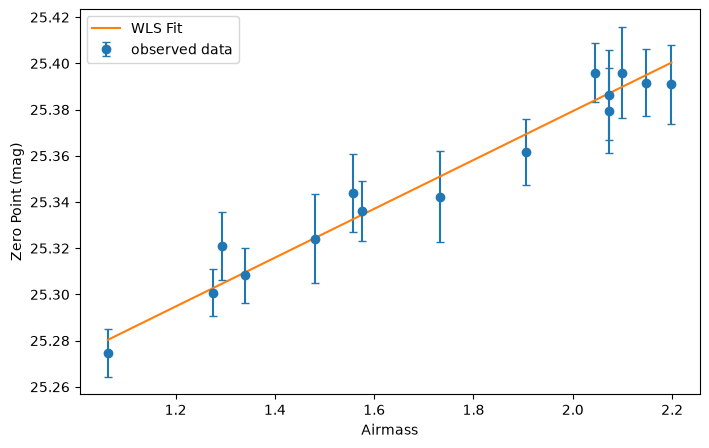

k = 0.10570201913425772  +-  0.00958363249266364  mag/airmass
m0 = 25.167920957862535  +-  0.015937589996132484  mag


In [2]:
# 1a: your work here
d = load('p1a_extinction')

X = d['airmass'].to_numpy()
m = d['zeropoint_mag'].to_numpy()
sigma = d['sigma_quoted_mag'].to_numpy()

A = np.column_stack([X, np.ones_like(X)])

w = []
for i in sigma:
    wi = 1/(i**2)
    w.append(wi)
w = np.array(w)

W = np.diag(w)
cov = np.linalg.inv(A.T @ W @ A)
sigma_k = np.sqrt(cov[0,0])
theta = cov @ A.T @ W @ m

k = theta[0]
m0 = theta[1]
sigma_m0 = np.sqrt(cov[1, 1])

plt.figure(figsize=(8,5))
plt.errorbar(X, m, yerr=sigma, fmt='o', capsize = 3, label = 'observed data')
plt.plot(X, k*X + m0, label = 'WLS Fit')
plt.xlabel('Airmass')
plt.ylabel('Zero Point (mag)')
plt.legend()
plt.show()

print("k =", k, " +- ", sigma_k, " mag/airmass")
print("m0 =", m0, " +- ", sigma_m0,  " mag")

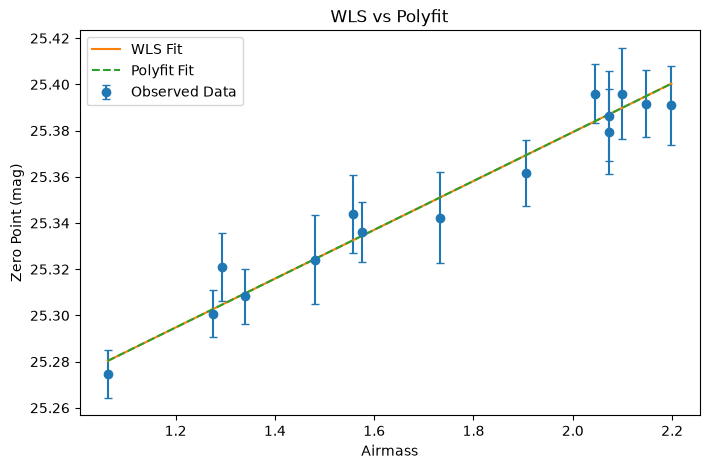

k (polyfit) =  0.10570201913431881  +-  0.005336070657643625 mag/airmass
k (calculated) = 0.10570201913425772  +-  0.00958363249266364  mag/airmass


In [3]:
coeff, cov_poly = np.polyfit(X, m, 1, w=1/sigma, cov = True)
k_poly = coeff[0]
sigma_k_poly = np.sqrt(cov_poly[0,0])

plt.figure(figsize=(8, 5))

plt.errorbar(X, m, yerr=sigma, fmt='o', capsize=3,label='Observed Data')

plt.plot(X, k*X + m0, label='WLS Fit')

plt.plot(X, coeff[0]*X + coeff[1], '--',label='Polyfit Fit')

plt.xlabel('Airmass')
plt.ylabel('Zero Point (mag)')
plt.title('WLS vs Polyfit')
plt.legend()
plt.show()

print("k (polyfit) = ", k_poly, " +- ", sigma_k_poly, "mag/airmass")
print("k (calculated) =", k, " +- ", sigma_k, " mag/airmass")

Explain exactly what polyfit did to get a different number (read its documentation for cov).

The k-values are near identical, but their respective sigmas are not. That is because np.polyfit scales the matrix by chi^2/dof, with dof = M - (deg + 1). In the calculation, we did not multiply by the reduced chi^2, but the np.polyfit does. 

In essence, the calculation assumes that the uncertainties are correct, while np.polyfit scales them based on the observed scatter. 


In [4]:
m_model = k*X + m0
chi2 = np.sum(((m - m_model)/sigma)**2)
dof = len(m) - 2
chi2_reduced = chi2/dof

print("Chi-squared:", chi2)
print("Degrees of freedom:", dof)
print("Reduced chi-squared:", chi2_reduced)

Chi-squared: 4.030196235557972
Degrees of freedom: 13
Reduced chi-squared: 0.31001509504292096


In [5]:
p_small = stats.chi2.cdf(chi2, dof)
p_large = stats.chi2.sf(chi2, dof)

print("P(chi2 <= observed):", p_small)
print("P(chi2 >= observed):", p_large)

P(chi2 <= observed): 0.009134080323919906
P(chi2 >= observed): 0.9908659196760801


How probable is a chi2 this large or this small if the quoted errors were right?

The likelihood for getting or smaller this chi2 value is 0.91%, which is highly unlikely. 


In [6]:
cov_expected = cov * chi2_reduced

print("Expected polyfit covariance:")
print(cov_expected)

print("Actual polyfit covariance:")
print(cov_poly)

print("Do they agree?", np.allclose(cov_expected, cov_poly))

coeff_unscaled, cov_unscaled = np.polyfit(
    X, m, 1, w=1/sigma, cov='unscaled'
)

sigma_k_unscaled = np.sqrt(cov_unscaled[0,0])

print("Manual WLS:", sigma_k)
print("Polyfit unscaled:", sigma_k_unscaled)
print("Polyfit scaled:", sigma_k_poly)

Expected polyfit covariance:
[[ 2.84736501e-05 -4.60486243e-05]
 [-4.60486243e-05  7.87459345e-05]]
Actual polyfit covariance:
[[ 2.84736501e-05 -4.60486243e-05]
 [-4.60486243e-05  7.87459345e-05]]
Do they agree? True
Manual WLS: 0.00958363249266364
Polyfit unscaled: 0.00958363249266366
Polyfit scaled: 0.005336070657643625


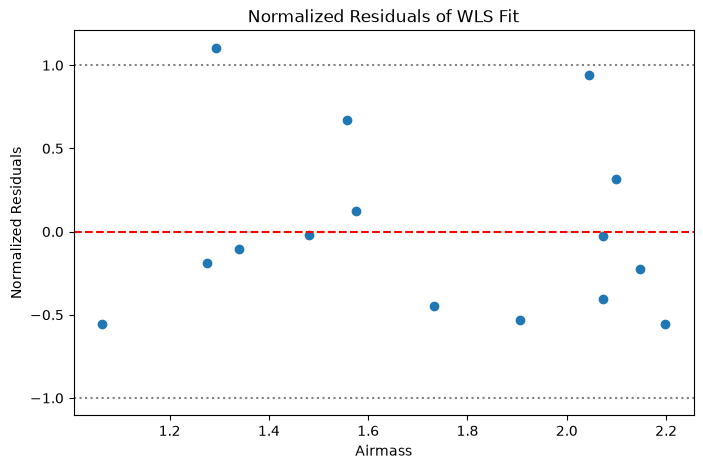

In [7]:
residuals = (m - m_model) / sigma

plt.figure(figsize=(8, 5))
plt.scatter(X, residuals)
plt.axhline(0, color='red', linestyle='--')
plt.axhline(1, color='gray', linestyle=':')
plt.axhline(-1, color='gray', linestyle=':')
plt.xlabel('Airmass')
plt.ylabel('Normalized Residuals')
plt.title('Normalized Residuals of WLS Fit')
plt.show()

**ANSWER:**

Report the error bar on k you'd quote, and justify it. What does your answer to (3) tell you about the pipeline's error bars?

k (polyfit) =  0.10570201913431881  +-  0.005336070657643625 mag/airmass

I would report the k uncertainty with the polyfit rather than the calculated k uncertainty. The reduced chi2 estimates that the probability of reproducing these results is 0.91%, which suggests that the pipeline overestimated the measured uncertainties. The residual graph above also suggests that the observed measurements are overestimated. 

### 1b - The centroid (`p1b_centroid.csv`)

A classmate measured the position of a star from `n_photons` photons, each landing at a position drawn from a Gaussian of width `psf_sigma_arcsec` around the true position. They report an error on the position of `quoted_sigma_x0_arcsec`, from a clever weighting scheme they found online.

1. Compute the Cramér-Rao bound on the error of any unbiased estimator of the position (Lab 02).
2. Is the quoted error possible? If not, say what the classmate's number must mean instead, and name two concrete mistakes that would produce an error bar this small.

In [8]:
d = load('p1b_centroid')

psf_sigma = d['psf_sigma_arcsec'].iloc[0]
N = d['n_photons'].iloc[0]
quoted_sigma = d['quoted_sigma_x0_arcsec'].iloc[0]

sigma_crb = psf_sigma / np.sqrt(N)
print("Cramér-Rao bound:", sigma_crb, "arcsec")
print("Classmate's uncertainty:", quoted_sigma, "arcsec")

Cramér-Rao bound: 0.08228335890694177 arcsec
Classmate's uncertainty: 0.0459931 arcsec


In [9]:
d

,psf_sigma_arcsec,n_photons,quoted_sigma_x0_arcsec
0,1.53718,349,0.045993


In [10]:
sigma_crb_incorrect = psf_sigma / (N)
print('sigma_crd incorrect: ', sigma_crb_incorrect, ' arcsec')

N_wrong = (psf_sigma/quoted_sigma)**2
print("number of photons: ", N_wrong)

sigma_crd incorrect:  0.004404527220630373  arcsec
number of photons:  1117.0280664626105


**ANSWER:**

Since the quoted error is smaller than the CRB, the classmate's error is not possible.

1) The classmate may have double-counted photons in their calculations. If we set the sigma_crb to what the classmate found, and solve for N, we get 1117 photons.

2) The classmate could have written the formula incorrectly. If we divide by N instead of N^1/2, we get something quite similar to their error. 

### 1c - The transit depth's error bar (`p1c_profile.csv`)

A transit-depth fit produced this profile: columns `depth_ppt` (the depth, in parts per thousand) and `minus2lnL` ($-2\ln L$ at that depth, other parameters fixed at their best values). A classmate took the second derivative of `minus2lnL` at its minimum and reported $\sigma = 1/\sqrt{d^2(-2\ln L)/d\,\textrm{depth}^2}$.

1. Find the best depth and the correct $1\sigma$ error from the curvature. Is the classmate's error bar right? If not, by what factor is it off, and why?
2. Read the $\Delta(-2\ln L) = 1$ interval directly off the profile. Is it symmetric? Compare it with your curvature answer.
3. If the classmate quotes $\pm$ their $\sigma$ on many independent datasets, what fraction of those intervals contain the true depth? Predict it, then check it with a simulation (a few thousand fake best-fit depths drawn around a truth you choose, using your correct $\sigma$).

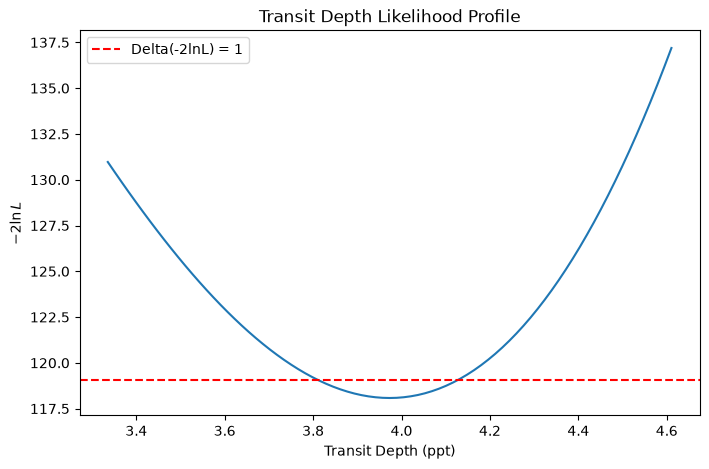

Best Depth:  3.97311  ppt
Curvature:  79.72349805620203 ppt^-2
Correct uncertainty: 0.15838783583034116 ppt
Classmate uncertainty: 0.11199711277309586 ppt
Ratio: 1.414213562373095
Left boundary: 3.809788556701031 ppt
Right boundary: 4.128632413793104 ppt


In [12]:
d = load('p1c_profile')

minus2lnL = d['minus2lnL'].to_numpy()
depth = d['depth_ppt'].to_numpy()

idx_min = np.argmin(minus2lnL)
depth_best = depth[idx_min]
thres = minus2lnL[idx_min] + 1

plt.figure(figsize=(8,5))
plt.plot(depth, minus2lnL)
plt.axhline(thres, color='red', linestyle='--', label='Delta(-2lnL) = 1')
plt.legend()
plt.xlabel('Transit Depth (ppt)')
plt.ylabel(r'$-2\ln L$')
plt.title('Transit Depth Likelihood Profile')
plt.show()

print('Best Depth: ', depth_best, ' ppt')
first_derivative = np.gradient(minus2lnL, depth)
second_derivative = np.gradient(first_derivative, depth)
curvature = second_derivative[idx_min]
print("Curvature: ", curvature, "ppt^-2")
sigma_depth = np.sqrt(2 / curvature)
sigma_classmate = 1 / np.sqrt(curvature)

print("Correct uncertainty:", sigma_depth, "ppt")
print("Classmate uncertainty:", sigma_classmate, "ppt")
print("Ratio:", sigma_depth / sigma_classmate)



left = np.interp(thres, minus2lnL[:idx_min+1][::-1], depth[:idx_min+1][::-1])
right = np.interp(thres, minus2lnL[idx_min:], depth[idx_min:])
print("Left boundary:", left, "ppt")
print("Right boundary:", right, "ppt")

The classmate's error is not correct. The classmate is off by 1.414, which is about np.sqrt(2). That means in their sigma calculations, they did 1/np.sqrt(second derivative) rather than np.sqrt(2/second derivative). 

In [13]:
min_profile = minus2lnL[idx_min]
thres = min_profile + 1
depth_left = depth[:idx_min]
profile_left = minus2lnL[:idx_min]

sigma_lower = depth_best - left
sigma_upper = right - depth_best

print("Curveture uncertainty:", sigma_depth, "ppt")
print("Lower uncertainty:", sigma_lower, "ppt")
print("Upper uncertainty:", sigma_upper, "ppt")

Curveture uncertainty: 0.15838783583034116 ppt
Lower uncertainty: 0.16332144329896936 ppt
Upper uncertainty: 0.15552241379310416 ppt


The interval is slightly asymmetric, but the estimated uncertainties are quite close to the curveture result. 

In [14]:
a = sigma_classmate / sigma_depth
expected_coverage = 2 * stats.norm.cdf(a) - 1
print("Expected coverage:", expected_coverage)

true_depth = depth_best
n_sim = 5000
rng = np.random.default_rng(42)
fake_depths = rng.normal(loc=true_depth, scale=sigma_depth, size=n_sim)

covered = ((fake_depths - sigma_classmate <= true_depth) &
(fake_depths + sigma_classmate >= true_depth))
simulated_coverage = np.mean(covered)
print("Expected coverage:", expected_coverage)
print("Simulated coverage:", simulated_coverage)

Expected coverage: 0.5204998778130467
Expected coverage: 0.5204998778130467
Simulated coverage: 0.5276


**ANSWER:**

Since the classmate underestimated by 1.414, their interval contains the true transit depth only 52% of the time, rather than 68%. The simulation with 5000 datasets demonstrates this as well, producing a similar coverage. 

### 1d - The companion mass (`p1d_mass_samples.csv`)

These are 8000 posterior samples of the mass of an unseen companion, `M2_Msun`. Three classmates report its uncertainty as (i) the variance of the samples, (ii) the 84th percentile minus the 16th, and (iii) the standard deviation divided by $\sqrt{8000}$.

1. Report the mass as a median with its 16th-84th percentile error bars, in solar masses.
2. For each of (i)-(iii): what quantity is it actually, what are its units, and by roughly what factor is it wrong as a $1\sigma$ error bar?
3. Is a symmetric $\pm$ error bar appropriate for this posterior? If not, show why.

Median mass: 5.882680000000001 Msun
Lower uncertainty: 1.1770916000000007 Msun
Upper uncertainty: 1.4588971999999991 Msun


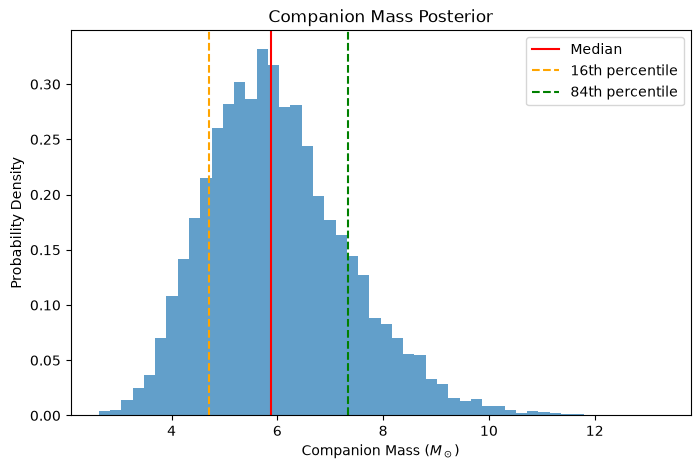

In [15]:
d = load('p1d_mass_samples')

mass = d['M2_Msun'].to_numpy()

begin = np.percentile(mass, 16)
middle = np.percentile(mass, 50)
end = np.percentile(mass, 84)

sigma_lower = middle - begin
sigma_upper = end - middle

print("Median mass:", middle, "Msun")
print("Lower uncertainty:", sigma_lower, "Msun")
print("Upper uncertainty:", sigma_upper, "Msun")

plt.figure(figsize=(8, 5))
plt.hist(mass, bins=50, density=True, alpha=0.7)
plt.axvline(middle, color='red', linestyle='-', label='Median')
plt.axvline(begin, color='orange', linestyle='--', label='16th percentile')
plt.axvline(end, color='green', linestyle='--', label='84th percentile')
plt.xlabel(r'Companion Mass ($M_\odot$)')
plt.ylabel('Probability Density')
plt.title('Companion Mass Posterior')
plt.legend()
plt.show()

In [16]:
variance = np.var(mass)
std = np.std(mass)

i = np.var(mass)
ii = end - begin
iii = np.std(mass) / 8000
print("(i) Variance:", i, "Msun^2")
print("(ii) Percentile width:", ii, "Msun")
print("(iii) Std / 8000:", iii, "Msun")

print (' ')
factor_i = variance / std
factor_ii = (end - begin) / std
factor_iii = std / (std / 8000)

print("Factor (i):", factor_i)
print("Factor (ii):", factor_ii)
print("Factor (iii):", factor_iii)

(i) Variance: 1.8102518950163367 Msun^2
(ii) Percentile width: 2.6359888 Msun
(iii) Std / 8000: 0.0001681820021870065 Msun
 
Factor (i): 1.3454560174960521
Factor (ii): 1.9591787213570024
Factor (iii): 8000.0


i) variance is M_sun^2, and mass is M_sun, so you cannot just apply np.var to the mass to get the uncertainty.

ii) reports the entire interval rather than just 68%

iii) by dividing by 8000, they made the uncertainty too small. 

As shown in the histogram, the posterior distribution is right-skewed, with the longer tail towards higher masses. The lower and upper uncertainty are quite different. Therefore, asymmetric uncertainities are better for this. 

### 1e - The slope at fixed intercept (`p1e_slope_intercept_samples.csv`)

Posterior samples of a slope and an intercept form a line fit. A classmate fixed the intercept at its best value, refit only the slope, and quoted the slope's error from that 1-D fit.

1. Compute the slope's error bar the classmate got (the spread of the slope *at fixed intercept*), and the marginal one (the spread of the slope with the intercept marginalized over).
2. Compute their ratio, and the correlation coefficient $\rho$ of the samples. How does the ratio depend on $\rho$? Plot the samples and draw both error bars on the plot.
3. When is the classmate's number the right one to quote? One sentence.

In [17]:
d = load('p1e_slope_intercept_samples')
slope = d['slope'].to_numpy()
intercept = d['intercept'].to_numpy()

sigma_marg = np.std(slope)
corr = np.corrcoef(slope, intercept)
rho = corr[0, 1]

sigma_cond = sigma_marg * np.sqrt(1 - rho**2)

print("Marginal uncertainty:", sigma_marg)
print("Conditional uncertainty:", sigma_cond)
print("Correlation coefficient:", rho)



Marginal uncertainty: 0.04183060673641855
Conditional uncertainty: 0.0183725790719897
Correlation coefficient: -0.8983825754870258


Ratio:  0.4392137840064885


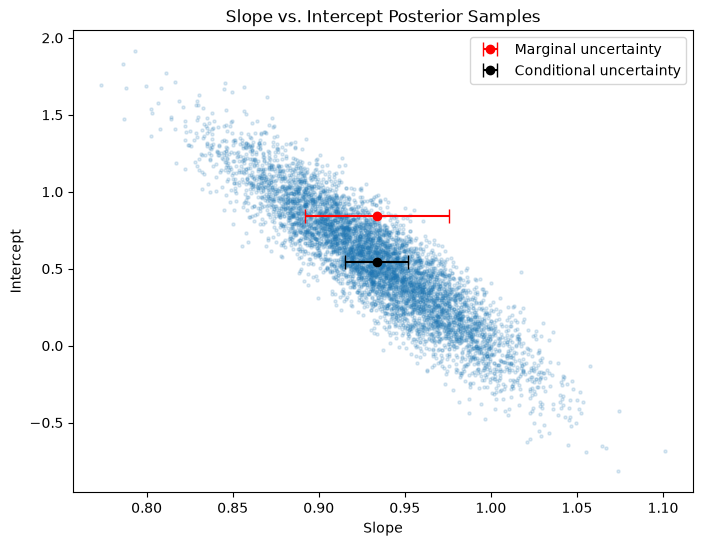

In [18]:
ratio = sigma_cond / sigma_marg
print('Ratio: ', ratio)

slope_mean = np.mean(slope)
intercept_mean = np.mean(intercept)


plt.figure(figsize=(8, 6))
plt.scatter(slope, intercept, alpha=0.15, s=5)
plt.errorbar(slope_mean, intercept_mean + 0.3,
             xerr=sigma_marg, fmt='o', color='red',
             capsize=5, label='Marginal uncertainty')
plt.errorbar(slope_mean, intercept_mean,
             xerr=sigma_cond, fmt='o', color='black',
             capsize=5, label='Conditional uncertainty')
plt.legend()
plt.xlabel('Slope')
plt.ylabel('Intercept')
plt.title('Slope vs. Intercept Posterior Samples')
plt.show()

**ANSWER:**

The classmate's one is the right one to quote when the intercept is known. 

## Part 2: 250 supernovae and a step (45 pts)

Type Ia supernovae are standardizable candles: their peak brightness, corrected for how fast they fade and for their color, measures distance well enough to have discovered cosmic acceleration. Your file `p2_pantheon_sne.csv` holds 250 real SNe Ia from the Pantheon+ compilation (Scolnic et al. 2022, ApJ 938, 113; [Brout et al. 2022](https://arxiv.org/abs/2202.04077), ApJ 938, 110), all at redshift $0.023 < z < 0.15$. For each supernova, a light-curve fit (SALT2) gives:

- `mB`: the peak apparent magnitude in the B band, and `mB_err`;
- `x1`: the light-curve *stretch* (broader light curves are brighter), and `x1_err`;
- `c`: the *color* (redder supernovae are fainter, from dust and intrinsically), and `c_err`;
- `cov_mB_x1`, `cov_mB_c`, `cov_x1_c`: the covariances between those three, from the same light-curve fit;
- `z`: the redshift; `host_logmass`, `host_logmass_err`: $\log_{10}$ of the host galaxy's stellar mass in solar masses, and its error.

The standardized brightness is the **Tripp relation**,

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10),$$

where $M$ is the absolute magnitude of a "standard" SN Ia, $\mu(z)$ the distance modulus, $\Theta$ is 1 for hosts more massive than $10^{10}\,M_\odot$ and 0 otherwise, and $\gamma$ is the **host-mass step**. Supernovae in massive hosts appear to be brighter after standardization (Kelly et al. 2010; Sullivan et al. 2010); whether the step is real, and why, matters for supernova dark-energy measurements. In this form, a step that makes supernovae in massive hosts brighter has $\gamma < 0$; the published value is about $\gamma \approx -0.06$ mag. So the question for your sample is whether you need $\gamma$ at all.

There are two more things you'll need. At these redshifts the galaxies' own motions (peculiar velocities, about 250 km/s) shift $z$, and so $\mu$; add $\sigma_{\mu,\rm pec} = \frac{5}{\ln 10}\frac{250\ {\rm km/s}}{c\,z}$ to each supernova's variance. And no supernova is a perfect standard candle: add an intrinsic scatter $\sigma_{\rm int}$, a free parameter. Use a flat $\Lambda$CDM distance modulus with $H_0 = 70$ km/s/Mpc and $\Omega_m = 0.3$ (`astropy.cosmology.FlatLambdaCDM(H0=70, Om0=0.3).distmod(z)`); $M$ absorbs the choice of $H_0$.

We planted between **two and four contaminants** in your file - objects whose `mB` we made fainter by more than a magnitude, so they are not standard SNe Ia any more (think of a mis-classified peculiar supernova). Their names are not in the file. Real data have a few real outliers too, so not everything far from the line is planted.

### 2a - Look at the data (5 pts)

1. Compute $\mu(z)$ and plot the **Hubble residuals** $m_B - \mu(z)$ against $x_1$, against $c$, and against `host_logmass`.
2. Which way do the $x_1$ and $c$ trends go? Is that the sign the Tripp relation expects? Two or three sentences.
3. The raw trend with host mass may not have the sign of $\gamma$. Why not? (Plot $x_1$ against host mass.)
4. Can you see any of the contaminants?
5. What units do $\alpha$ and $\beta$ have?

Distance modulus (mag): [39.0364438  38.72043571 38.30359164 39.09487317 38.91335685]


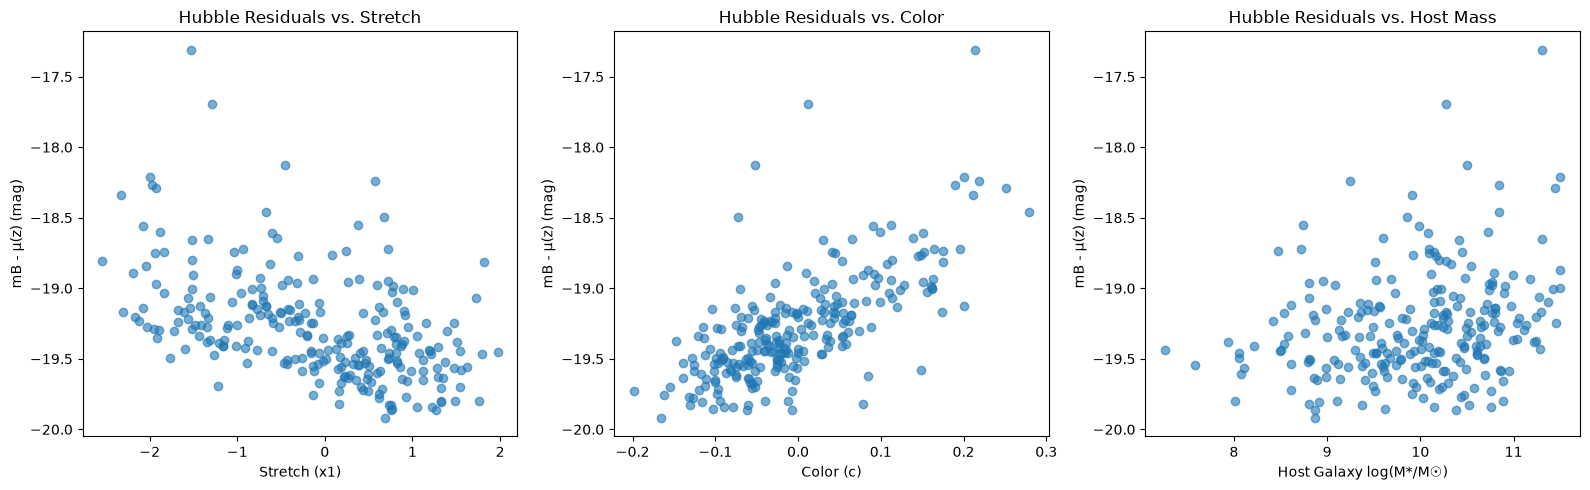

In [19]:
from astropy.cosmology import FlatLambdaCDM
d = load('p2_pantheon_sne')
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

z = d['z'].to_numpy()

mu = cosmo.distmod(z).value
mB = d['mB'].to_numpy()
print("Distance modulus (mag):", mu[:5])
residuals = mB - mu


x1 = d['x1'].to_numpy()
c = d['c'].to_numpy()
host_mass = d['host_logmass'].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].scatter(x1, residuals, alpha=0.6)
axes[0].set_xlabel('Stretch (x1)')
axes[0].set_ylabel('mB - μ(z) (mag)')
axes[0].set_title('Hubble Residuals vs. Stretch')


axes[1].scatter(c, residuals, alpha=0.6)
axes[1].set_xlabel('Color (c)')
axes[1].set_ylabel('mB - μ(z) (mag)')
axes[1].set_title('Hubble Residuals vs. Color')


axes[2].scatter(host_mass, residuals, alpha=0.6)
axes[2].set_xlabel('Host Galaxy log(M*/M☉)')
axes[2].set_ylabel('mB - μ(z) (mag)')
axes[2].set_title('Hubble Residuals vs. Host Mass')

plt.tight_layout()
plt.show()

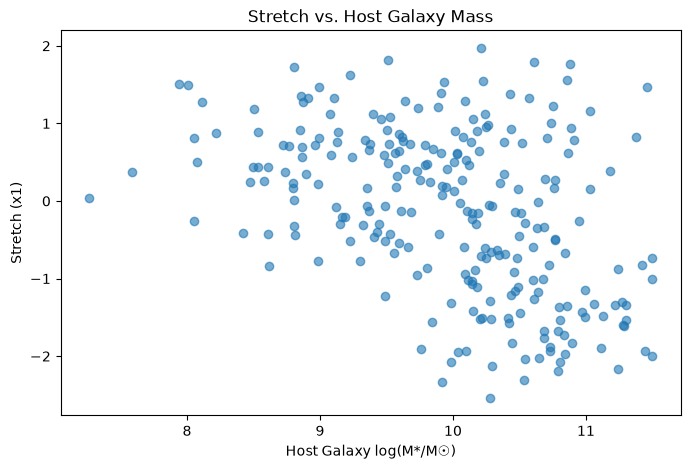

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(host_mass, x1, alpha=0.6)

plt.xlabel('Host Galaxy log(M*/M☉)')
plt.ylabel('Stretch (x1)')
plt.title('Stretch vs. Host Galaxy Mass')

plt.show()

Which way do the X1 and c trends go? Is that the sign the Tripp relation expects? Two or three sentences.

The stretch parameter and host galaxy mass are negatively correlated because as the mass increases, the stretch decreases. This is consistent with the Tripp relation. 

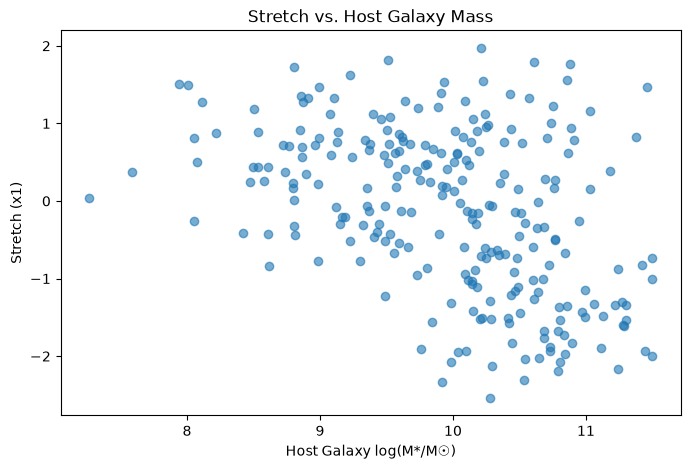

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(host_mass, x1, alpha=0.6)

plt.xlabel('Host Galaxy log(M*/M☉)')
plt.ylabel('Stretch (x1)')
plt.title('Stretch vs. Host Galaxy Mass')

plt.show()

The raw trend with host mass may not have the sign of gamma. Why not? (Plot x against host mass.)

Same graph as before showing the same negative correlation. Lower stretch is associated dimmer supernovae (directions) and lower stretch is associated with higher mass in this graph. That means the brightness trends could be caused by stretch and not mass. With a correction for stretch, the effect of the galaxy mass gamma could change or be negative. 

Can you see any of the contaminants?

A few possible ones in the Hubble Residuals vs. Color, but nothing that I can confidently confirm. 

What units do alpha and beta have?

alpha: mags/stretch

beta: dimensionless

### 2b - The likelihood (10 pts)

The parameters are $\theta = (M, \alpha, \beta, \gamma, \sigma_{\rm int})$. Each supernova's variance is

$$\sigma_i^2 = \mathbf{v}^T C_i\,\mathbf{v} + \sigma_{\mu,{\rm pec},i}^2 + \sigma_{\rm int}^2, \qquad \mathbf{v} = (1, \alpha, -\beta),$$

where $C_i$ is that supernova's $3\times3$ covariance of $(m_B, x_1, c)$.

1. Write out $\mathbf{v}^T C_i\,\mathbf{v}$ term by term, and explain in one sentence why the off-diagonal terms are there.
2. Write the log-likelihood. Remember the $\ln\sigma_i^2$ term - the variance depends on the parameters.
3. State a prior for every parameter, and justify each in one line.
4. Decide whether to sample $\ln\sigma_{\rm int}$ or $\sigma_{\rm int}$, and say why.
5. Decide what to do about the contaminants. You may model them or remove them, but say how you found them and what a cut would cost you.

v.T = vector of coefficents, (1, alpha, -beta)

Ci = covariance matrix
Off diagonal terms here are the covariances, so whether the measurements are related or not.

v = vector of coefficents (1, alpha, -beta)

The Gaussian log-likelihood is:

$$
\ln L(\theta) = -\frac{1}{2}\sum_{i=1}^{250}
\left[
\frac{(m_{B,i}-m_{B,\mathrm{model},i})^2}{\sigma_i^2}
+\ln(2\pi\sigma_i^2)
\right]
$$

In [22]:
def log_likelihood(theta):
    M, alpha, beta, gamma, log_sigma_int = theta
    sigma_int = np.exp(log_sigma_int)
    host_step = (host_mass >= 10).astype(float)
    model = M + mu - alpha*x1 + beta*c + gamma*host_step
    variance_measurement = (
        d['mB_err'].to_numpy()**2
        + alpha**2 * d['x1_err'].to_numpy()**2
        + beta**2 * d['c_err'].to_numpy()**2
        + 2*alpha * d['cov_mB_x1'].to_numpy()
        - 2*beta * d['cov_mB_c'].to_numpy()
        - 2*alpha*beta * d['cov_x1_c'].to_numpy())
    sigma_pec = (5 / np.log(10)) * (250 / (299792.458 * z))
    variance = variance_measurement + sigma_pec**2 + sigma_int**2
    if np.any(variance <= 0) or not np.all(np.isfinite(variance)):
        return -np.inf
    residuals = mB - model
    log_like = -0.5 * np.sum(
        residuals**2 / variance + np.log(2*np.pi*variance))
    return log_like

M: [-21, -17] includes a broad range of typical Ia abs mags

alpha: [[0, 0.5] includes average value with substantial range to let data determine alpha

B: [0,6] typical value is 3, so this should include all of the values, needs to be positive. 

gamma: [-0.5-0.5] includes -0.06 mag, this range allows for bright and dim supernovae

ln sigma_int: [ln(0.01), ln(1)] represents instrinsic scatter, range ensures that there is a lot of variation without forcing the scatter to a particular value. 

I am sampling ln sigma int because the intrinsic scatter cannot be negative. The ln ensures that it is not a negative value, because if we sample sigma int directly, it could be negative. 

I am implementing a mixture model. While it does not remove the contaminants, it will weight them less than genuine values. 

Cutting out data could result in a loss of real values, which would impact the end result. 

Contaminant fraction: 4/250 = 0.015
Brightness contaminant: +1.5 mag
Additional scatter: 0.5 mag

### 2c - Sampling and convergence (12 pts)

1. Find the maximum a posteriori point. Then run **four independent chains** from starting points spread wider than the posterior (you choose how, and say how you chose). Any sampler is fine - your own Metropolis, `emcee` (one ensemble per chain), or `PyMC`.
2. Report $\hat R$ and the effective sample size for every parameter (`arviz.rhat`, `arviz.ess`, or `arviz.summary`), and say what values would have made you run longer.
3. Make a corner plot, and quote $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 16th-84th percentile error bars.
4. Which parameters are correlated strongly? Comment on why. Then fix $M$ at its MAP value, refit $\gamma$, and compare that $\sigma_\gamma$ with the marginal one (cf. 1e).

`ArviZ` 1.x (install it with `conda install -c conda-forge pymc arviz`, as in `INSTALL.txt`) takes your chains as a dictionary of arrays shaped (chain, draw): `idata = az.from_dict({'posterior': {'alpha': a, 'beta': b}})`, then `az.summary(idata)`.

In [23]:
import numpy as np
import emcee
from scipy.optimize import minimize

def log_likelihood_mixture(theta):
    M, alpha, beta, gamma, log_sigma_int = theta
    sigma_int = np.exp(log_sigma_int)
    host_step = (host_mass >= 10).astype(float)
    model = M + mu - alpha*x1 + beta*c + gamma*host_step
    variance_measurement = (
        d['mB_err'].to_numpy()**2
        + alpha**2 * d['x1_err'].to_numpy()**2
        + beta**2 * d['c_err'].to_numpy()**2
        + 2*alpha * d['cov_mB_x1'].to_numpy()
        - 2*beta * d['cov_mB_c'].to_numpy()
        - 2*alpha*beta * d['cov_x1_c'].to_numpy())
    sigma_pec = (5 / np.log(10)) * (250 / (299792.458 * z))
    variance = variance_measurement + sigma_pec**2 + sigma_int**2

    if np.any(variance <= 0) or not np.all(np.isfinite(variance)):
        return -np.inf

    residuals = mB - model

    f_out = 0.014
    delta_out = 1.5
    sigma_out = 0.5

    log_normal = -0.5 * (residuals**2 / variance + np.log(2*np.pi*variance))
    variance_out = variance + sigma_out**2

    log_outlier = -0.5 * ((residuals - delta_out)**2 / variance_out + np.log(2*np.pi*variance_out))
    log_like = np.sum(
        np.logaddexp(
            np.log1p(-f_out) + log_normal,
            np.log(f_out) + log_outlier))

    return log_like

def log_prior(theta):
    M, alpha, beta, gamma, log_sigma_int = theta
    if (-21 < M < -17 and
        0 < alpha < 0.5 and
        0 < beta < 6 and
        -0.5 < gamma < 0.5 and
        np.log(0.01) < log_sigma_int < np.log(1)):
        return 0.0
    return -np.inf

def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood_mixture(theta)

def neg_log_posterior(theta):
    lp = log_posterior(theta)
    if not np.isfinite(lp):
        return 1e100
    return -lp

theta0 = np.array([-19.3, 0.14, 3.1, -0.06, np.log(0.1)])
bounds = [(-20.999, -17.001), (0.001, 0.499), (0.001, 5.999), (-0.499, 0.499), (np.log(0.0101), np.log(0.999))]

result = minimize(neg_log_posterior, theta0, method='Nelder-Mead', options={'maxiter': 20000})
theta_map = result.x

print("MAP optimization successful:", result.success)
print("MAP parameters:", theta_map)
print("MAP log posterior:", log_posterior(theta_map))

nchains = 4
nwalkers = 32
nsteps = 10000
ndim = len(theta_map)

rng = np.random.default_rng(42)

start_spread = np.array([0.1, 0.03, 0.3, 0.05, 0.3])

chains = []
for chain in range(nchains):
    p0 = theta_map + rng.normal(0, start_spread, size=(nwalkers, ndim))
    for j in range(nwalkers):
        while not np.isfinite(log_prior(p0[j])):
            p0[j] = theta_map + rng.normal(0, start_spread)

    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)
    sampler.run_mcmc(p0, nsteps, progress=True)
    chains.append(sampler.get_chain())
    print(f"Chain {chain + 1} acceptance fraction:",
          np.mean(sampler.acceptance_fraction))
chains = np.array(chains)

print("Chains shape:", chains.shape)

MAP optimization successful: True
MAP parameters: [-19.27216643   0.15477484   2.8938381   -0.06645466  -2.30770394]
MAP log posterior: 110.09395038107367


100%|███████████████████████████████████| 10000/10000 [00:28<00:00, 346.25it/s]


Chain 1 acceptance fraction: 0.5512312500000001


100%|███████████████████████████████████| 10000/10000 [00:28<00:00, 356.43it/s]


Chain 2 acceptance fraction: 0.550821875


100%|███████████████████████████████████| 10000/10000 [00:28<00:00, 354.75it/s]


Chain 3 acceptance fraction: 0.5507124999999999


100%|███████████████████████████████████| 10000/10000 [00:28<00:00, 356.87it/s]

Chain 4 acceptance fraction: 0.551671875
Chains shape: (4, 10000, 32, 5)


I am using emcee.EnsembleSampler

start_spread = np.array([0.1, 0.03, 0.3, 0.05, 0.3])

M: 0.3mag, allows values above and below MAP estimate

alpha: 0.03, allows broad range with some constraint

B: 0.3, allows a lot of variation around 3, with some constraint

gamma: 0.1mag, broader than the host-mass effect.

ln sigma int: 0.3, allows intrinsic scatter to vary a lot, with some constraint


In [24]:
import arviz as az
import xarray as xr
import numpy as np

burnin = 2500
post = chains[:, burnin:, :, :]
post = post.transpose(0, 2, 1, 3).reshape(128, -1, 5)
param_names = ['M', 'alpha', 'beta', 'gamma', 'log_sigma_int']

posterior = xr.Dataset({
    name: (('chain', 'draw'), post[:, :, i])
    for i, name in enumerate(param_names)
})
rhat = az.rhat(posterior)
ess_bulk = az.ess(posterior, method='bulk')
ess_tail = az.ess(posterior, method='tail')

for name in param_names:
    print(
        f"{name}: "
        f"R-hat = {rhat[name].values.item():.4f}, "
        f"ESS bulk = {ess_bulk[name].values.item():.0f}, "
        f"ESS tail = {ess_tail[name].values.item():.0f}")

M: R-hat = 1.0078, ESS bulk = 16194, ESS tail = 33554
alpha: R-hat = 1.0073, ESS bulk = 16297, ESS tail = 32302
beta: R-hat = 1.0079, ESS bulk = 16289, ESS tail = 33150
gamma: R-hat = 1.0072, ESS bulk = 15773, ESS tail = 32888
log_sigma_int: R-hat = 1.0084, ESS bulk = 16060, ESS tail = 29548


I would run it longer if R was above than 1.01, or if the effective sample size was too low, or if the chains had poor mixing. 

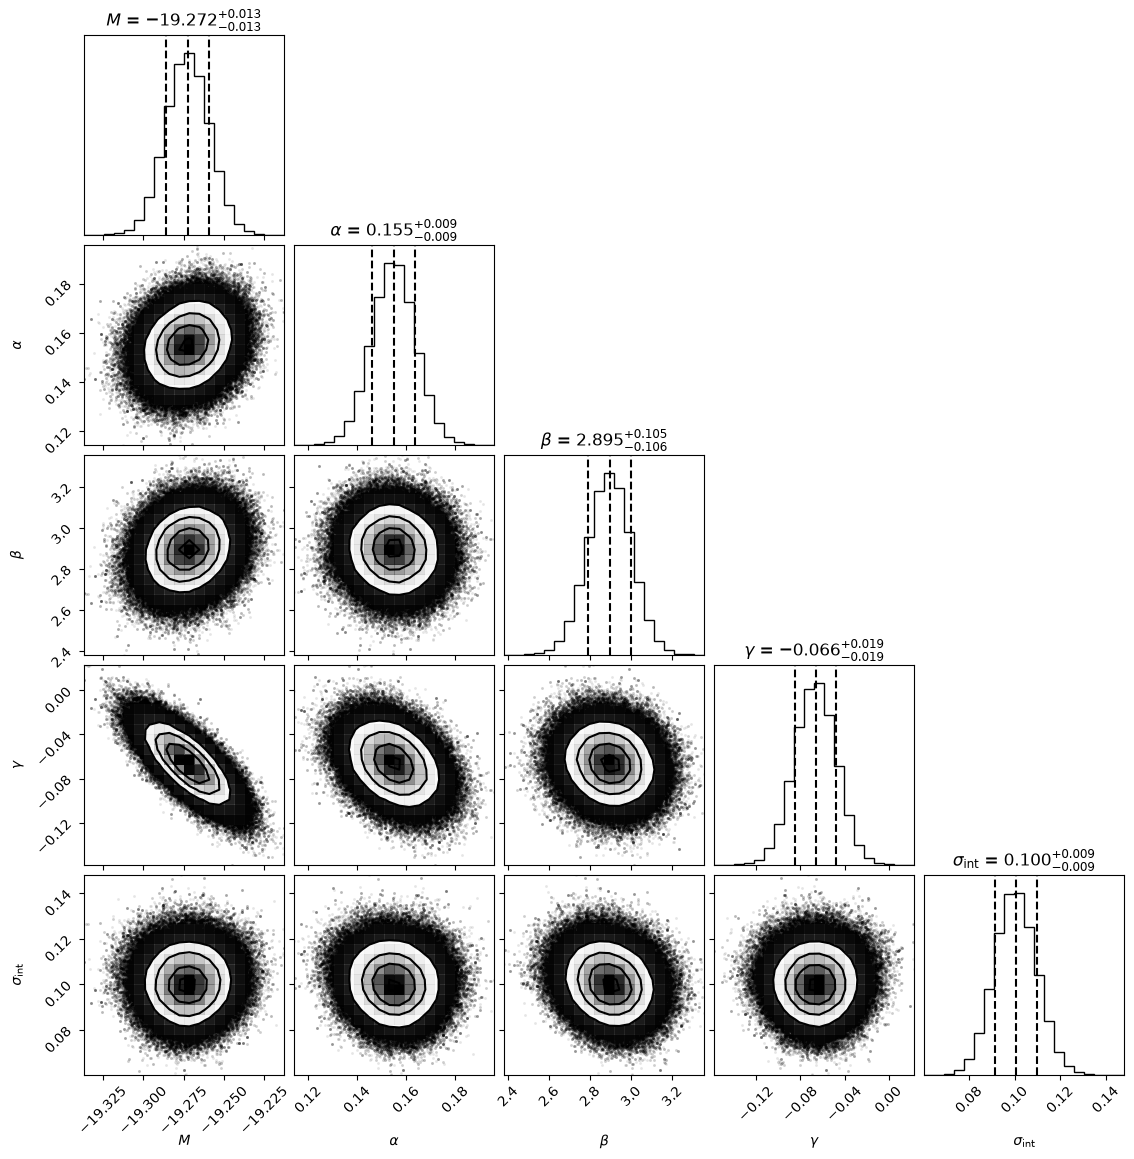

M: -19.2725 -0.0132 +0.0133
alpha: 0.1549 -0.0088 +0.0088
beta: 2.8946 -0.1062 +0.1048
gamma: -0.0662 -0.0187 +0.0186
sigma_int: 0.1004 -0.0090 +0.0093


In [25]:
import numpy as np
import corner
import matplotlib.pyplot as plt

burnin = 2500
samples = chains[:, burnin:, :, :].reshape(-1, 5)
samples[:, 4] = np.exp(samples[:, 4])

labels = [r"$M$",r"$\alpha$",r"$\beta$",r"$\gamma$",r"$\sigma_{\mathrm{int}}$"]
fig = corner.corner(samples, labels=labels, quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt=".3f")
plt.show()
param_names = ["M", "alpha", "beta", "gamma", "sigma_int"]
for i, name in enumerate(param_names):
    p16, p50, p84 = np.percentile(samples[:, i], [16, 50, 84])
    lower_error = p50 - p16
    upper_error = p84 - p50
    print(
        f"{name}: {p50:.4f} "
        f"-{lower_error:.4f} "
        f"+{upper_error:.4f}")

In [26]:
corr_matrix = np.corrcoef(samples.T)

print(np.round(corr_matrix, 3))

[[ 1.     0.182  0.171 -0.753  0.025]
 [ 0.182  1.    -0.068 -0.348 -0.073]
 [ 0.171 -0.068  1.    -0.132 -0.171]
 [-0.753 -0.348 -0.132  1.    -0.001]
 [ 0.025 -0.073 -0.171 -0.001  1.   ]]


M and gamma have a strong negative correlation (-0.753). This is due to the Tripp relation, so if M increases, gamma decreases. 

In [27]:
M_fixed = theta_map[0]

def log_posterior_fixed(theta_free):
    alpha, beta, gamma, log_sigma_int = theta_free
    theta_full = np.array([M_fixed, alpha, beta, gamma, log_sigma_int])
    return log_posterior(theta_full)

def neg_log_posterior_fixed(theta_free):
    lp = log_posterior_fixed(theta_free)
    if not np.isfinite(lp):
        return 1e100
    return -lp


result_fixed = minimize(neg_log_posterior_fixed, theta_map[1:], method='Nelder-Mead', options={'maxiter': 20000})

print("Optimization successful:", result_fixed.success)
print("Fixed-M MAP parameters:", result_fixed.x)
nwalkers = 32
nsteps = 5000
ndim_fixed = 4

rng = np.random.default_rng(123)
spread_fixed = np.array([0.02, 0.2, 0.03, 0.2])
p0 = result_fixed.x + rng.normal(0, spread_fixed, size=(nwalkers, ndim_fixed))
for j in range(nwalkers):
    while not np.isfinite(log_posterior_fixed(p0[j])):
        p0[j] = result_fixed.x + rng.normal(0, spread_fixed)

sampler_fixed = emcee.EnsembleSampler(nwalkers, ndim_fixed, log_posterior_fixed)
sampler_fixed.run_mcmc(p0, nsteps, progress=True)
fixed_samples = sampler_fixed.get_chain(discard=2500, flat=True)
gamma_fixed = fixed_samples[:, 2]

gamma_fixed_16, gamma_fixed_50, gamma_fixed_84 = np.percentile(gamma_fixed, [16, 50, 84])
sigma_gamma_fixed = np.std(gamma_fixed)

gamma_marginal = samples[:, 3]
sigma_gamma_marginal = np.std(gamma_marginal)

print("\nGamma with M fixed:")
print(f"Median: {gamma_fixed_50:.5f} mag")
print(f"16th–84th percentile: {gamma_fixed_16:.5f}, {gamma_fixed_84:.5f} mag")
print(f"Conditional uncertainty: {sigma_gamma_fixed:.5f} mag")

print("\nGamma with M marginalized:")
print(f"Marginal uncertainty: {sigma_gamma_marginal:.5f} mag")

print("\nRatio:")
print(f"Conditional / Marginal = {sigma_gamma_fixed / sigma_gamma_marginal:.3f}")

Optimization successful: True
Fixed-M MAP parameters: [ 0.15477752  2.89384827 -0.06646054 -2.30762549]


100%|█████████████████████████████████████| 5000/5000 [00:14<00:00, 346.24it/s]


Gamma with M fixed:
Median: -0.06656 mag
16th–84th percentile: -0.07913, -0.05424 mag
Conditional uncertainty: 0.01253 mag

Gamma with M marginalized:
Marginal uncertainty: 0.01879 mag

Ratio:
Conditional / Marginal = 0.667


The uncertainty after fixing M at its MAP value and refitting the parameters decreased, with a ratio of 0.660, which agrees with the expected ratio of 0.658.

### 2d - Model comparison (10 pts)

Compare $M_0$ ($\gamma = 0$) with $M_1$ ($\gamma$ free).

1. Compute $2\ln B_{1,0}$ with the Laplace approximation (Day 13), with a prior on $\gamma$ you state and defend. How does it change if that prior is twice as wide?
2. Compute $\textrm{BIC}_0 - \textrm{BIC}_1$ for comparison.
3. How strong is your answer on Day 8's scale (0-2 weak, 2-6 positive, 6-10 strong, above 10 very strong)? Compare $\gamma$ with the published $-0.06$ mag. Could your 250 supernovae have detected a step that size? (One way: your $\sigma_\gamma$ tells you how many $\sigma$ a $-0.06$ step would be.)

In [28]:
import numpy as np
from scipy.optimize import minimize

theta1 = theta_map.copy()
logL1 = log_likelihood_mixture(theta1)
def make_theta0(params):
    M, alpha, beta, log_sigma_int = params
    return np.array([M, alpha, beta, 0.0, log_sigma_int])

def neg_logL0(params):
    theta = make_theta0(params)
    if not np.isfinite(log_prior(theta)):
        return 1e100
    return -log_likelihood_mixture(theta)

result0 = minimize(neg_logL0, theta_map[[0, 1, 2, 4]], method="Nelder-Mead", options={"maxiter": 20000})
theta0 = make_theta0(result0.x)
logL0 = log_likelihood_mixture(theta0)

print("M0 optimization successful:", result0.success)
print("M0 best-fit parameters:", theta0)
print("M1 log likelihood:", logL1)
print("M0 log likelihood:", logL0)

def hessian(f, x, h=1e-4):
    x = np.asarray(x, dtype=float)
    n = len(x)
    H = np.zeros((n, n))
    eye = np.eye(n) * h
    for i in range(n):
        H[i, i] = ( f(x + eye[i])- 2*f(x) + f(x - eye[i])) / h**2
        for j in range(i + 1, n):
            H[i, j] = (f(x + eye[i] + eye[j]) - f(x + eye[i] - eye[j]) - f(x - eye[i] + eye[j]) + f(x - eye[i] - eye[j])) / (4*h**2)
            H[j, i] = H[i, j]
    return H

def neg_logL1(theta):
    return -log_likelihood_mixture(theta)

H1 = hessian(neg_logL1, theta1)
H0 = hessian(neg_logL0, result0.x)

sign1, logdet1 = np.linalg.slogdet(H1)
sign0, logdet0 = np.linalg.slogdet(H0)

print("Positive Hessian determinants:", sign1 > 0, sign0 > 0)
print("Positive Hessian eigenvalues:", np.all(np.linalg.eigvalsh(H1) > 0), np.all(np.linalg.eigvalsh(H0) > 0))

#original uniform gamma prior: [-0.5, 0.5]
gamma_prior_width = 1.0

d1 = 5
d0 = 4

lnB10 = ((logL1 - logL0) + 0.5*(d1 - d0)*np.log(2*np.pi) - 0.5*(logdet1 - logdet0) - np.log(gamma_prior_width))

two_lnB10 = 2*lnB10
two_lnB10_double = two_lnB10 - 2*np.log(2)

print(f"2 ln B10 (original prior): {two_lnB10:.3f}")
print(f"2 ln B10 (double width):  {two_lnB10_double:.3f}")

M0 optimization successful: True
M0 best-fit parameters: [-19.30748104   0.14347946   2.84406914   0.          -2.25684072]
M1 log likelihood: 110.09395038107367
M0 log likelihood: 103.87240907637235
Positive Hessian determinants: True True
Positive Hessian eigenvalues: True True
2 ln B10 (original prior): 6.173
2 ln B10 (double width):  4.786


I used [-0.5, 0.5] as the prior on gamma, which allows both positive and negative host-mass effects, and it is much higher than the expected -0.06mag, so variation without much constraint is possible. 

If the prior is twice as wide, 2lnB decreases to 4.786, which indicates some dependence on the prior. The result does favor the model with the gamma free though. 

In [29]:
N = len(d)
k0 = 4
k1 = 5

BIC0 = k0 * np.log(N) - 2 * logL0
BIC1 = k1 * np.log(N) - 2 * logL1

delta_BIC = BIC0 - BIC1

print(f"BIC0 (gamma = 0): {BIC0:.3f}")
print(f"BIC1 (gamma free): {BIC1:.3f}")
print(f"BIC0 - BIC1: {delta_BIC:.3f}")

BIC0 (gamma = 0): -185.659
BIC1 (gamma free): -192.581
BIC0 - BIC1: 6.922


Based on the day 8 lecture, it is strong. My gamma is consistent with the published value. My value for gamma is -0.0660 +- 0.01884 mag. 

Yes, it could have detected a step that size, as the sigma is 3.18 sigma.

In [30]:
gamma_published = -0.06
gamma_measured = -0.0660
sigma_gamma = 0.01884
significance_published = abs(gamma_published) / sigma_gamma
significance_measured = abs(gamma_measured) / sigma_gamma
difference = abs(gamma_measured - gamma_published)

print(f"Published gamma: {gamma_published:.4f} mag")
print(f"Measured gamma: {gamma_measured:.4f} mag")
print(f"Uncertainty in gamma: {sigma_gamma:.5f} mag")
print(f"Difference from published value: {difference:.4f} mag")
print(f"Expected detection significance: {significance_published:.2f} sigma")
print(f"Measured detection significance: {significance_measured:.2f} sigma")

Published gamma: -0.0600 mag
Measured gamma: -0.0660 mag
Uncertainty in gamma: 0.01884 mag
Difference from published value: 0.0060 mag
Expected detection significance: 3.18 sigma
Measured detection significance: 3.50 sigma


### 2e - Testing your pipeline (8 pts)

Design one test of your pipeline that would come out differently if your pipeline were wrong, and run it. State **before** you run it what result would count as a failure. One suggestion: generate fake supernovae at your redshifts, stretches and colors from parameters you choose (including a $\gamma$ you choose), fit 30 or more such datasets (maximum-likelihood fits with curvature error bars are fine here; you don't need MCMC for each), and check how often your 68% intervals contain the truth.

I am going to run a coverage test, where I simulate data with known parameters to see if the methods I used recovers them. I will check to see if 68% of 30 datasets match. 

Failure is less than 15 or greater than 26. 

In [32]:
rng_validation = np.random.default_rng(457)

theta_true = theta_map.copy()

M_true, alpha_true, beta_true, gamma_true, log_sigma_true = theta_true
sigma_int_true = np.exp(log_sigma_true)

host_step = (host_mass >= 10).astype(float)
mB_true = (
    M_true + mu
    - alpha_true * x1
    + beta_true * c
    + gamma_true * host_step
)

variance_measurement_true = (
    d['mB_err'].to_numpy()**2
    + alpha_true**2 * d['x1_err'].to_numpy()**2
    + beta_true**2 * d['c_err'].to_numpy()**2
    + 2 * alpha_true * d['cov_mB_x1'].to_numpy()
    - 2 * beta_true * d['cov_mB_c'].to_numpy()
    - 2 * alpha_true * beta_true * d['cov_x1_c'].to_numpy()
)

sigma_pec = (5 / np.log(10)) * (250 / (299792.458 * z))

variance_true = (
    variance_measurement_true
    + sigma_pec**2
    + sigma_int_true**2
)

# Contaminant model
f_out = 0.014
delta_out = 1.5
sigma_out = 0.5

def generate_synthetic_data():
    noise = rng_validation.normal(
        0, np.sqrt(variance_true)
    )

    is_outlier = rng_validation.random(len(mB_true)) < f_out

    noise[is_outlier] += rng_validation.normal(
        delta_out, sigma_out, size=np.sum(is_outlier)
    )

    return mB_true + noise

In [33]:
mB_original = mB.copy()

n_simulations = 30
nwalkers = 32
nsteps = 5000
burnin = 2500
ndim = 5

gamma_results = []
coverage_results = []
failed_fits = []

rng_mcmc = np.random.default_rng(457)

try:
    for i in range(n_simulations):
        mB = generate_synthetic_data()
        result_sim = minimize(neg_log_posterior, theta_true, method="Nelder-Mead", options={"maxiter": 20000})
        if not result_sim.success:
            failed_fits.append(i + 1)
            print(f"Simulation {i+1}: MAP optimization failed")
            continue
        theta_fit = result_sim.x
        spread = np.array([0.02, 0.01, 0.1, 0.02, 0.1])

        p0 = theta_fit + rng_mcmc.normal(0, spread, size=(nwalkers, ndim))
        for j in range(nwalkers):
            while not np.isfinite(log_posterior(p0[j])):
                p0[j] = theta_fit + rng_mcmc.normal(0, spread)
        sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)
        sampler.run_mcmc(p0, nsteps, progress=False)

        posterior = sampler.get_chain(discard=burnin, flat=True)
        gamma_samples = posterior[:, 3]

        gamma_16, gamma_50, gamma_84 = np.percentile(gamma_samples, [16, 50, 84])

        covered = gamma_16 <= gamma_true <= gamma_84

        gamma_results.append((gamma_50, gamma_16, gamma_84))
        coverage_results.append(covered)

        print(
            f"Simulation {i+1:2d}: "
            f"gamma = {gamma_50:.4f}, "
            f"68% CI = [{gamma_16:.4f}, {gamma_84:.4f}], "
            f"covered = {covered}")

finally:
    mB = mB_original.copy()

n_valid = len(coverage_results)
n_covered = sum(coverage_results)

print("\nVALIDATION RESULTS")
print(f"Successful fits: {n_valid}/{n_simulations}")
print(f"Intervals containing true gamma: {n_covered}/{n_valid}")
print(f"Observed coverage: {n_covered/n_valid:.3f}")
print("Expected coverage: 0.680")

passed = (n_valid == 30 and 15 <= n_covered <= 26)

print("Validation:", "PASS" if passed else "FAIL")

Simulation  1: gamma = -0.0881, 68% CI = [-0.1053, -0.0705], covered = False
Simulation  2: gamma = -0.0903, 68% CI = [-0.1081, -0.0709], covered = False
Simulation  3: gamma = -0.0667, 68% CI = [-0.0852, -0.0484], covered = True
Simulation  4: gamma = -0.0764, 68% CI = [-0.0931, -0.0591], covered = True
Simulation  5: gamma = -0.0683, 68% CI = [-0.0877, -0.0485], covered = True
Simulation  6: gamma = -0.0650, 68% CI = [-0.0830, -0.0471], covered = True
Simulation  7: gamma = -0.0749, 68% CI = [-0.0931, -0.0557], covered = True
Simulation  8: gamma = -0.0829, 68% CI = [-0.1025, -0.0640], covered = True
Simulation  9: gamma = -0.0724, 68% CI = [-0.0912, -0.0545], covered = True
Simulation 10: gamma = -0.0894, 68% CI = [-0.1088, -0.0696], covered = False
Simulation 11: gamma = -0.0502, 68% CI = [-0.0680, -0.0312], covered = True
Simulation 12: gamma = -0.0627, 68% CI = [-0.0805, -0.0448], covered = True
Simulation 13: gamma = -0.0475, 68% CI = [-0.0663, -0.0290], covered = False
Simulati

**ANSWER:**
Here, 23/30 fits contained the true value, falling within my success parameters. While it was higher than 68%, it still fell within my acceptable range. 

## Part 3: The referee report (25 pts)

White dwarfs are the cores of dead stars like the Sun. Your file `p3_wd_masses.csv` holds 600 real DA (hydrogen-atmosphere) white dwarfs from the 100 pc sample of [Kilic et al. (2020)](https://arxiv.org/abs/2006.00323), ApJ 898, 84: `name`, `teff_K`, `mass_Msun`, `mass_err_Msun`. Most single white dwarfs have masses near $0.6\,M_\odot$; Kilic et al. report a narrow peak there plus an excess of more massive ones, around $0.7$-$0.9\,M_\odot$, which merger products alone do not explain.

The notebook `labs/midterm/ai_solution.ipynb` fits your masses with a two-population model using `emcee`. Run it from that directory, after setting `NETID` in its first cell. It runs top to bottom and the plots look nice, but it's wrong in at least three substantive ways - and if you don't look at your data, you'll fool yourself the same way.

### 3a - The report (20 pts)

1. **Identify** at least three substantive errors (not style; "it used 32 walkers and I'd use 48" is not one).
2. **Demonstrate** each on *your* file: show, with a number or a plot, what the error does to the answer. A demonstration can come out negative: if an error doesn't move your numbers, show that, and say what it would take for it to matter.
3. **State** the correct treatment, and run it where you can.

Total white dwarfs: 600
White dwarfs removed: 12
Minimum removed mass: 0.116
Maximum removed mass: 1.358


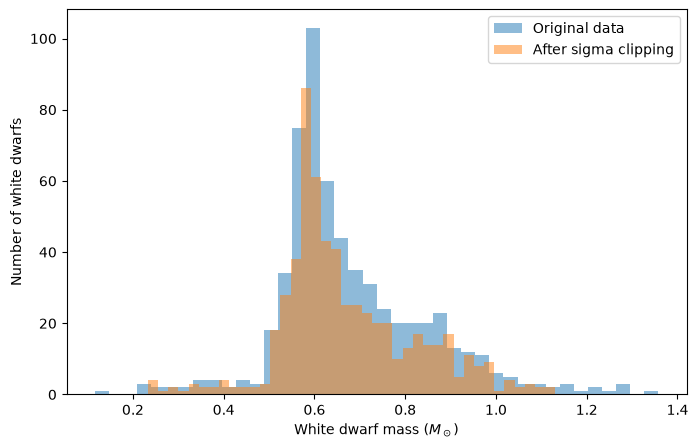

In [34]:
#Mistake 1: The sigma clipping is wrong as it assumes a Gaussian distribution. 
# However, the directions state that there is an excess of massive ones around 0.7-0.9 M_sun,
# meaning that it is asymmetric. 

#AI Code:

d = np.genfromtxt(f'data/{NETID}/p3_wd_masses.csv', delimiter=',', names=True, dtype=None, encoding='utf-8')
mass = d['mass_Msun']
med, sd = np.median(mass), np.std(mass)
keep = np.abs(mass - med) < 3 * sd
m = mass[keep]

print("Total white dwarfs:", len(mass))
print("White dwarfs removed:", np.sum(~keep))
print("Minimum removed mass:", np.min(mass[~keep]) if np.any(~keep) else "None")
print("Maximum removed mass:", np.max(mass[~keep]) if np.any(~keep) else "None")

plt.figure(figsize=(8, 5))

plt.hist(mass, bins=40, alpha=0.5, label="Original data")
plt.hist(mass[keep], bins=40, alpha=0.5, label="After sigma clipping")

plt.xlabel(r"White dwarf mass ($M_\odot$)")
plt.ylabel("Number of white dwarfs")
plt.legend()
plt.show()

# Here it is obvious that it is overcutting. 

In [35]:
from scipy import stats
import numpy as np
import emcee

def log_prob(p, m):
    mu1, s1, mu2, s2, f = p
    if not (0.3 < mu1 < 1.3 and
            0.3 < mu2 < 1.3 and
            0.005 < s1 < 0.5 and
            0.005 < s2 < 0.5 and
            0 < f < 1):
        return -np.inf
    return np.sum(np.log(f * stats.norm.pdf(m, mu1, s1) + (1 - f) * stats.norm.pdf(m, mu2, s2)))

med, sd = np.median(mass), np.std(mass)
keep = np.abs(mass - med) < 3 * sd
m = mass[keep]

lo, hi = m[m < 0.7], m[m >= 0.7]

p0 = np.array([
    lo.mean(), lo.std(),
    hi.mean(), hi.std(),
    lo.size / m.size])

nwalk, ndim = 32, 5

np.random.seed(42)
start_original = p0 + 1e-3 * np.random.randn(nwalk, ndim)

sampler_original = emcee.EnsembleSampler(nwalk, ndim, log_prob, args=(m,))

sampler_original.run_mcmc(start_original, 5000, progress=True)

flat = sampler_original.get_chain(discard=2500, flat=True)

m_corrected = mass.copy()

np.random.seed(43)
start_corrected = p0 + 1e-3 * np.random.randn(nwalk, ndim)

sampler_corrected = emcee.EnsembleSampler(nwalk, ndim, log_prob, args=(m_corrected,))

sampler_corrected.run_mcmc(start_corrected, 5000, progress=True)

samples_corrected = sampler_corrected.get_chain(discard=2500, flat=True)
names = ['mu1', 'sigma1', 'mu2', 'sigma2', 'f']

best_original = np.median(flat, axis=0)
best_corrected = np.median(samples_corrected, axis=0)

print("\nParameter       AI clipped       Full dataset")

for i, name in enumerate(names):
    print(
        f"{name:<15} "
        f"{best_original[i]:.4f}           "
        f"{best_corrected[i]:.4f}")

print("\nOriginal acceptance fraction:",
      np.mean(sampler_original.acceptance_fraction))

print("Corrected acceptance fraction:",
      np.mean(sampler_corrected.acceptance_fraction))

#The treatment I suggest is a mixture model. The full dataset increases,
# and the mu2 also increases. This means that real higher mass white dwarfs 
# are kept.

100%|█████████████████████████████████████| 5000/5000 [00:09<00:00, 512.82it/s]


Parameter       AI clipped       Full dataset
mu1             0.5933           0.5959
sigma1          0.0370           0.0402
mu2             0.7207           0.7412
sigma2          0.1709           0.1958
f               0.3890           0.4175

Original acceptance fraction: 0.55291875
Corrected acceptance fraction: 0.54883125


In [36]:
#Mistake 2:

#AI Code
best = np.median(flat, axis=0)
mu1, s1, mu2, s2, f = best
print(f"Population 1: mean mass {mu1:.3f} +/- {s1:.3f} Msun ({100 * f:.0f}% of white dwarfs)")
print(f"Population 2: mean mass {mu2:.3f} +/- {s2:.3f} Msun ({100 * (1 - f):.0f}% of white dwarfs)")


# Here, the AI assumes that sigma 1 and 2 are the uncertainty for mu1 and mu2. 
# However, those are not the uncertainties of their estimated population means, but the 
# spread of individual white dwarf varies in the population. 
# Reporting it in this way is false, and would cause issues in publication. 

# Treatment:
for i, name in [(0, "Population 1"), (2, "Population 2")]:
    p16, p50, p84 = np.percentile(flat[:, i], [16, 50, 84])

    print(f"{name}:")
    print(f"Mean mass = {p50:.4f} Msun")
    print(f"Lower uncertainty = {p50 - p16:.4f} Msun")
    print(f"Upper uncertainty = {p84 - p50:.4f} Msun")
    print()

# Taking into account the upper and lower uncertainties, the error is higher. 

Population 1: mean mass 0.593 +/- 0.037 Msun (39% of white dwarfs)
Population 2: mean mass 0.721 +/- 0.171 Msun (61% of white dwarfs)
Population 1:
Mean mass = 0.5933 Msun
Lower uncertainty = 0.0037 Msun
Upper uncertainty = 0.0039 Msun

Population 2:
Mean mass = 0.7207 Msun
Lower uncertainty = 0.0100 Msun
Upper uncertainty = 0.0106 Msun



In [38]:
#Mistake 3:

# AI Code
# def gelman_rubin(x):                                
#     n, mchains = x.shape
#     B = n * np.var(x.mean(axis=0), ddof=1)
#     W = np.mean(np.var(x, axis=0, ddof=1))
#     return np.sqrt(((n - 1) / n * W + B / n) / W)

# names = ['mu1', 'sigma1', 'mu2', 'sigma2', 'f']
# for i, nm in enumerate(names):
#     print(f"R-hat({nm}) = {gelman_rubin(chain[:, :, i]):.3f}")
# print("All R-hat < 1.1: the chains have converged.")


# This is an issue because it was treating emcee walkers as independent chains. 
# emcee walkers interact, so they can't be independent. Treating them as such
# results in inaccurate Rs. 


In [39]:
import numpy as np
import emcee
import arviz as az
import xarray as xr
import matplotlib.pyplot as plt

nchains = 4
nwalkers = 32
nsteps = 5000
burnin = 2500
ndim = 5

rng = np.random.default_rng(457)

starts = [p0, p0 + np.array([0.02, 0.01, 0.02, 0.01, -0.05]), p0 + np.array([-0.02, 0.01, 0.03, 0.02, 0.05]), p0 + np.array([0.01, 0.02, -0.02, 0.01, -0.03])]

chains_independent = []

for i in range(nchains):
    start = starts[i] + 0.005 * rng.normal(size=(nwalkers, ndim))
    for j in range(nwalkers):
        while not np.isfinite(log_prob(start[j], m)):
            start[j] = starts[i] + 0.005 * rng.normal(size=ndim)
    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_prob, args=(m,))
    sampler.run_mcmc(start, nsteps, progress=True)
    chains_independent.append(sampler.get_chain())
    print(f"Ensemble {i+1} acceptance fraction:", np.mean(sampler.acceptance_fraction))
chains_independent = np.array(chains_independent)

print("Chain shape:", chains_independent.shape)


post = chains_independent[:, burnin:, 0, :]

names = ['mu1', 'sigma1', 'mu2', 'sigma2', 'f']

posterior = xr.Dataset({
    name: (('chain', 'draw'), post[:, :, i])
    for i, name in enumerate(names)})

rhat = az.rhat(posterior)
ess_bulk = az.ess(posterior, method='bulk')
ess_tail = az.ess(posterior, method='tail')

print("\nCORRECTED CONVERGENCE DIAGNOSTICS")

for name in names:
    print(
        f"{name}: "
        f"R-hat = {rhat[name].values.item():.4f}, "
        f"ESS bulk = {ess_bulk[name].values.item():.0f}, "
        f"ESS tail = {ess_tail[name].values.item():.0f}"
    )

100%|█████████████████████████████████████| 5000/5000 [00:09<00:00, 518.56it/s]


Ensemble 1 acceptance fraction: 0.53771875


100%|█████████████████████████████████████| 5000/5000 [00:10<00:00, 498.51it/s]


Ensemble 2 acceptance fraction: 0.52554375


100%|█████████████████████████████████████| 5000/5000 [00:09<00:00, 509.32it/s]


Ensemble 3 acceptance fraction: 0.5152125000000001


100%|█████████████████████████████████████| 5000/5000 [00:11<00:00, 428.78it/s]


Ensemble 4 acceptance fraction: 0.54905
Chain shape: (4, 5000, 32, 5)

CORRECTED CONVERGENCE DIAGNOSTICS
mu1: R-hat = 1.0281, ESS bulk = 199, ESS tail = 277
sigma1: R-hat = 1.0137, ESS bulk = 203, ESS tail = 360
mu2: R-hat = 1.0215, ESS bulk = 177, ESS tail = 351
sigma2: R-hat = 1.0299, ESS bulk = 168, ESS tail = 293
f: R-hat = 1.0288, ESS bulk = 171, ESS tail = 380


In [ ]:
# Here, the R values are higher than the acceptable threshold of 1.01. 

# The treatment would be this method, and running it until R dropped to 1.01 or less. 

### 3b - AI-use appendix (5 pts)

1. Which tools did you use, for what, what did they get wrong, and how did you catch it? "I used ChatGPT to help" is useless; "none" is fine if that's true. I promise I don't care which - just be honest about what you did.
2. What would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing, in two or three sentences.

**AI-USE APPENDIX:**
I used Chat.

I requested that Chat work with me as a tutor, meaning for every line it explained it to me or it gave me the opportunity to write it myself and checked it with me. 

Part 1:

I requested Chat to help me for this section. It provided me with some boilerplate code, but not all of it. I requested additional code to help me prove my choice for k in 1a (the residual graphs, the chi^2 calculations).

I requested all of the code for the plotting. It recommended a histogram for 1d, which I used. 


Part 2:
Chat continued working with me. Requested code for the plotting in 2a1.

Gave me the plotting code for 2a2.

Asked what the Tripp relation was. Asked about the question I had to answer for 2a2.

Asked about 2a4 because I got confused.

I asked for the function for log like in 2b2, and asked how I was supposed to write the equation in Jupyter lab, and it gave me the stuff to write it in markdown which was super nice.

Discussed the priors for 2b3 with Chat

Discussed modeling options with chat, and necessary values. 


Requested the boilerplate code for 2c1. 

Requested code for 2c2, requested debugging for 2c1.

Requested methods for lowering R to 1.01.

Requested code for 2c3

Discussed what parameters are related closely. 

Requested the code for 2d1
Discussed priors in 2d1.
Requested code for the rest of 2d.
Discussed outputs for each step in 2d. 

Part 3:
Confirmed mistake one with Chat. Requested code from chat to prove it. 

Discussed the .pdf in the second block of code in the ai solution. Requested code to prove it. Not enough for a significant error. 

AI pointed out that there was an issue with reporting in block 6 and I investigated
it. Discussed why that was an issue. Requested code to demonstrate error. 



End:
Requested debugging code after I ran all of the cells. 

When I requested code for 2e, rather than rerun my MCMC that I used earlier, it wanted to use a Gaussian to make things run faster. Had I not been closely working with it, then the testing of my pipeline would have been off entirely. 

Get started. You know how to do all of this. If not, there's something in a lab or class notebook that can help. Slack me with questions. Best of luck.